In [ ]:
!nvidia-smi



Tue Sep  9 07:27:14 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 30.2 MB/s eta 0:00:00


In [ ]:
from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()


Ultralytics 8.3.196 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 39.1/112.6 GB disk)


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="wUZAy7PRAIgtvl6r8QSo")
project = rf.workspace("detection-ifxlr").project("autism-7ywpu")
version = project.version(3)
dataset = version.download("yolov11")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.6/88.6 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 45.2 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to autism-3 in yolov11:: 100%|██████████| 28716/28716 [00:03<00:00, 9355.11it/s] 


In [ ]:
import yaml

# Specify the path to the YAML file
yaml_file_path = '/content/autism-3/data.yaml'

# Load the YAML file
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)

# Extract and display the class names
class_names = data['names']
print("Class Names:", class_names)

Class Names: ['Autistic', 'Non_Autistic']


In [ ]:
!yolo task=detect mode=train model=yolov8x.pt data= /content/autism-3/data.yaml epochs=20 imgsz=224 plots=True

Ultralytics 8.3.196 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/autism-3/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8x.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=1

In [ ]:

!yolo task=detect mode=val model= /content/runs/detect/train2/weights/best.pt data= /content/autism-3/data.yaml


Ultralytics 8.3.196 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 112 layers, 68,125,494 parameters, 0 gradients, 257.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 541.3±159.0 MB/s, size: 9.7 KB)
val: Scanning /content/autism-3/valid/labels.cache... 1688 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1688/1688 26.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 106/106 6.8it/s 15.6s
                   all       1688       1669      0.872      0.888      0.942      0.942
              Autistic        775        775      0.877      0.868      0.938      0.938
          Non_Autistic        894        894      0.866      0.907      0.946      0.946
Speed: 0.0ms preprocess, 6.4ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image
import cv2
import math
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
# Load the YOLO model
model = YOLO("/content/best.pt")

# Class names for the YOLO model
class_names = ['1', '2', '3', '4', '5', '6', '7', '8', '9', 'add', 'divide', 'minus', 'multiplication']


In [ ]:

# Load the image
input_image_path = '/content/Screenshot 2025-02-28 084001.png'  # Replace with the path to your input image
img = cv2.imread(input_image_path)

# Convert BGR to RGB for Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


0: 160x224 2 3s, 1 multiplication, 46.5ms
Speed: 12.3ms preprocess, 46.5ms inference, 364.4ms postprocess per image at shape (1, 3, 160, 224)


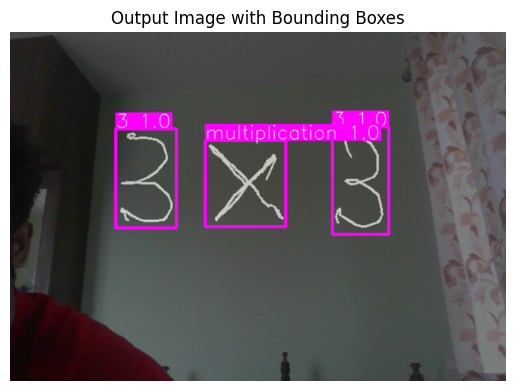

In [ ]:
results = model(img, stream=True)

# Process and display results
for r in results:
    boxes = r.boxes
    for box in boxes:
        x1, y1, x2, y2 = box.xyxy[0]
        x1, y1, x2, y2 = int(x1), int(y1), int(x2), int(y2)

        # Draw bounding box
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 255), 3)

        # Get confidence and class
        conf = math.ceil((box.conf[0] * 100)) / 100
        cls = int(box.cls[0])
        class_name = class_names[cls]
        label = f'{class_name} {conf}'

        # Get text size
        t_size = cv2.getTextSize(label, 0, fontScale=1, thickness=2)[0]
        c2 = x1 + t_size[0], y1 - t_size[1] - 3

        # Draw filled rectangle for label
        cv2.rectangle(img, (x1, y1), c2, [255, 0, 255], -1, cv2.LINE_AA)
        cv2.putText(img, label, (x1, y1 - 2), 0, 1, [255, 255, 255], thickness=1, lineType=cv2.LINE_AA)

# Convert image back to RGB for displaying with Matplotlib
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display the output image with bounding boxes
plt.imshow(img)
plt.axis('off')
plt.title('Output Image with Bounding Boxes')
plt.show()


0: 192x224 1 2, 1 3, 1 multiplication, 60.7ms
Speed: 2.1ms preprocess, 60.7ms inference, 2.2ms postprocess per image at shape (1, 3, 192, 224)
Detected Expression: 2*3
Evaluated Result: 6


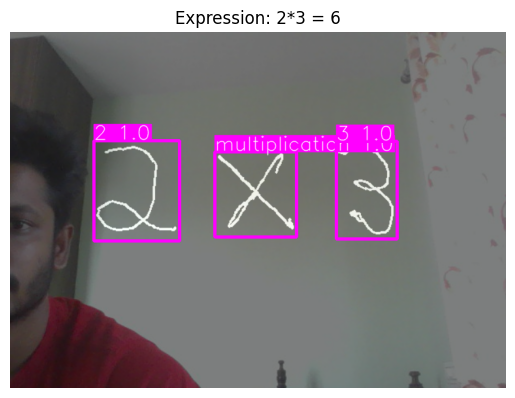

In [ ]:
from ultralytics import YOLO
import cv2
import math
import numpy as np
import matplotlib.pyplot as plt

# Load the YOLO model
model = YOLO("/content/best.pt")

# Class names for the YOLO model
class_names = ['1', '2', '3', '4', '5', '6', '7', '8', '9', 'add', 'divide', 'minus', 'multiplication']

# Mapping operators to symbols
operator_map = {
    'add': '+',
    'minus': '-',
    'multiplication': '*',
    'divide': '/'
}

# Load the image
input_image_path = '/content/Screenshot 2025-02-28 083928.png'  # Replace with your image path
img = cv2.imread(input_image_path)

# Convert BGR to RGB for Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

results = model(img, stream=True)

detected_elements = []

# Process and extract detected elements
for r in results:
    boxes = r.boxes
    for box in boxes:
        x1, y1, x2, y2 = box.xyxy[0]
        x1, y1, x2, y2 = int(x1), int(y1), int(x2), int(y2)

        # Get class and confidence
        conf = math.ceil((box.conf[0] * 100)) / 100
        cls = int(box.cls[0])
        class_name = class_names[cls]

        # Store detected element with position
        detected_elements.append((x1, class_name))

        # Draw bounding box
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 255), 3)

        # Label the box
        label = f'{class_name} {conf}'
        t_size = cv2.getTextSize(label, 0, fontScale=1, thickness=2)[0]
        c2 = x1 + t_size[0], y1 - t_size[1] - 3
        cv2.rectangle(img, (x1, y1), c2, [255, 0, 255], -1, cv2.LINE_AA)
        cv2.putText(img, label, (x1, y1 - 2), 0, 1, [255, 255, 255], thickness=1, lineType=cv2.LINE_AA)

# Convert image back to RGB for display
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Sort elements based on x position (left to right)
detected_elements.sort()

# Construct expression
expression = ""
for _, class_name in detected_elements:
    if class_name in operator_map:
        expression += operator_map[class_name]
    else:
        expression += class_name

# Evaluate the expression
try:
    result = eval(expression)
except Exception as e:
    result = "Error"

# Display expression and result
print(f"Detected Expression: {expression}")
print(f"Evaluated Result: {result}")

# Show image with bounding boxes
plt.imshow(img)
plt.axis('off')
plt.title(f'Expression: {expression} = {result}')
plt.show()


In [ ]:
import cv2
import math
import matplotlib.pyplot as plt

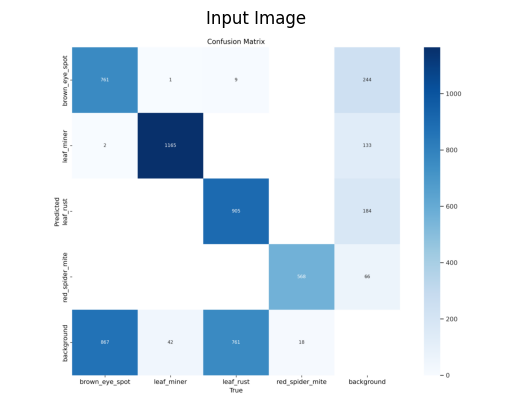

In [ ]:
# Load an input image
input_image_path = '/content/runs/detect/train/confusion_matrix.png'  # Replace with the path to your input image
img = cv2.imread(input_image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for Matplotlib

# Display the input image
plt.imshow(img)
plt.axis('off')
plt.title('Input Image')
plt.show()


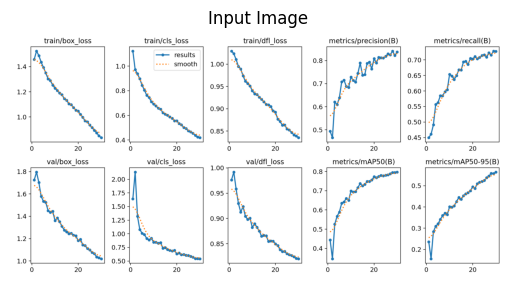

In [ ]:
# Load an input image
input_image_path = '/content/runs/detect/train/results.png'  # Replace with the path to your input image
img = cv2.imread(input_image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for Matplotlib

# Display the input image
plt.imshow(img)
plt.axis('off')
plt.title('Input Image')
plt.show()


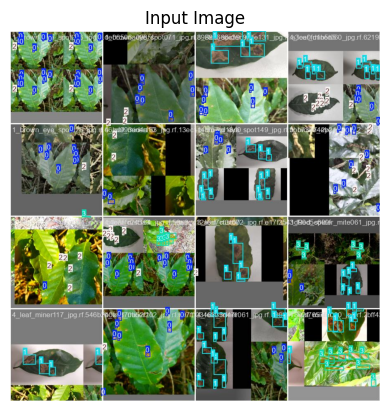

In [ ]:
# Load an input image
input_image_path = '/content/runs/detect/train/train_batch0.jpg'  # Replace with the path to your input image
img = cv2.imread(input_image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for Matplotlib

# Display the input image
plt.imshow(img)
plt.axis('off')
plt.title('Input Image')
plt.show()


In [ ]:
# Load a model
model = YOLO('/content/runs/detect/train/weights/best.pt')  # load a custom trained model

# Export the model
model.export(format='tflite')

Ultralytics YOLOv8.2.87 🚀 Python-3.10.12 torch-2.4.0+cu121 CPU (Intel Xeon 2.00GHz)
Model summary (fused): 268 layers, 68,127,420 parameters, 0 gradients, 257.4 GFLOPs

PyTorch: starting from '/content/runs/detect/train/weights/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 8, 1029) (130.3 MB)
requirements: Ultralytics requirements ['sng4onnx>=1.0.1', 'onnx_graphsurgeon>=0.3.26', 'onnx>=1.12.0', 'onnx2tf>1.17.5,<=1.22.3', 'onnxslim>=0.1.31', 'tflite_support', 'onnxruntime-gpu'] not found, attempting AutoUpdate...
Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.6/136.6 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 kB 245.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 259.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 435.0/435.0 kB 297.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 

100%|██████████| 1.11M/1.11M [00:00<00:00, 31.5MB/s]
Unzipping calibration_image_sample_data_20x128x128x3_float32.npy.zip to /content/calibration_image_sample_data_20x128x128x3_float32.npy...: 100%|██████████| 1/1 [00:00<00:00, 46.28file/s]


ONNX: starting export with onnx 1.16.2 opset 19...


ONNX: slimming with onnxslim 0.1.32...
ONNX: export success ✅ 6.2s, saved as '/content/runs/detect/train/weights/best.onnx' (260.0 MB)
TensorFlow SavedModel: starting TFLite export with onnx2tf 1.22.3...
TensorFlow SavedModel: export success ✅ 92.4s, saved as '/content/runs/detect/train/weights/best_saved_model' (650.2 MB)

TensorFlow Lite: starting export with tensorflow 2.17.0...
TensorFlow Lite: export success ✅ 0.0s, saved as '/content/runs/detect/train/weights/best_saved_model/best_float32.tflite' (260.0 MB)

Export complete (96.3s)
Results saved to /content/runs/detect/train/weights
Predict:         yolo predict task=detect model=/content/runs/detect/train/weights/best_saved_model/best_float32.tflite imgsz=224  
Validate:        yolo val task=detect model=/content/runs/detect/train/weights/best_saved_model/best_float32.tflite imgsz=224 data=/content/kape-2/data.yaml  
Visualize:       https://netron.app


'/content/runs/detect/train/weights/best_saved_model/best_float32.tflite'

Loading /content/runs/detect/train/weights/best_saved_model/best_float32.tflite for TensorFlow Lite inference...

image 1/1 /content/kape-2/test/images/1_brown_eye_spot003_jpg.rf.ab87944a45156c9c566210ea87b26efc.jpg: 224x224 3 brown_eye_spots, 526.4ms
Speed: 0.7ms preprocess, 526.4ms inference, 0.9ms postprocess per image at shape (1, 3, 224, 224)
Results saved to runs/detect/predict2


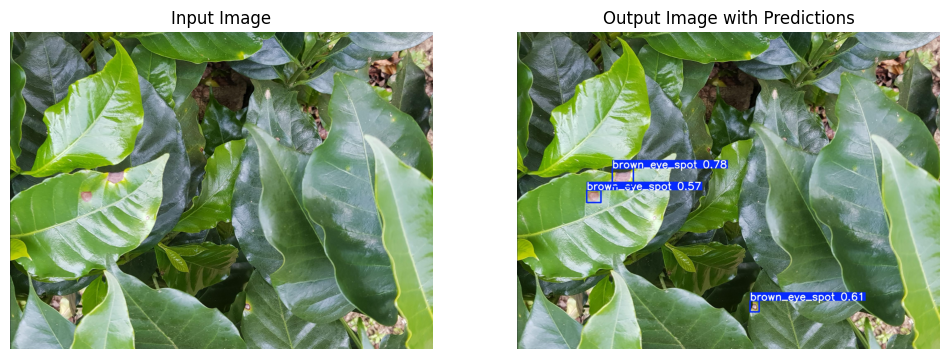

In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os

# Load a trained YOLO model
model = YOLO('/content/runs/detect/train/weights/best_saved_model/best_float32.tflite')

# Define the input image path
input_image_path = '/content/kape-2/test/images/1_brown_eye_spot003_jpg.rf.ab87944a45156c9c566210ea87b26efc.jpg'

# Run inference
results = model.predict(input_image_path, save=True, imgsz=224, conf=0.2)

# Define the output directory path
output_dir = 'runs/detect/predict'

# Find the output image file (assuming only one image is processed)
output_image_files = [f for f in os.listdir(output_dir) if f.endswith('.jpg') or f.endswith('.png')]
if not output_image_files:
    raise FileNotFoundError("No output image files found in the results directory.")

output_image_path = os.path.join(output_dir, output_image_files[0])

# Load and display the input image
input_image = cv2.imread(input_image_path)
input_image_rgb = cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))

# Display the input image
plt.subplot(1, 2, 1)
plt.title('Input Image')
plt.imshow(input_image_rgb)
plt.axis('off')

# Load and display the output image
output_image = cv2.imread(output_image_path)
output_image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

plt.subplot(1, 2, 2)
plt.title('Output Image with Predictions')
plt.imshow(output_image_rgb)
plt.axis('off')

plt.show()
